# 02 – Preprocessing and Feature Engineering Pipeline

**Dataset:** UJIIndoorLoc, UCI Machine Learning Repository (CC BY 4.0)  
**Scope:** Module 02 of the Indoor Wi-Fi Positioning Benchmark  

## Executive Summary & Objectives
In Wi-Fi fingerprinting, the raw measurements consist of Received Signal Strength Indicators (RSSI) collected across hundreds of distributed Wireless Access Points (WAPs). The raw data presents several distinctive challenges that directly impact machine learning models:

1. **Arbitrary Missing-Signal Convention:** When an access point is out of range or undetected, the raw dataset logs a sentinel value of `+100`. In reality, RSSI is measured in logarithmic decibels relative to one milliwatt (dBm) and is strictly negative (typically between $-104$ dBm and $-30$ dBm). Leaving undetected APs as $+100$ severely warps distance metrics in $k$-NN and introduces misleading gradients in linear and neural models.
2. **Extreme Sparsity:** Over 96% of entries in the 520-dimensional RSSI matrix are undetected. However, this absence of signal is not merely missing data; it is a strong physical signal indicating that the receiver is separated from those transmitters by distance, walls, or floors.
3. **Zero-Variance Features:** Dozens of WAPs installed across the university campus were never observed during the training data collection campaign, introducing redundant dimensionality.
4. **Information Density & Aggregation:** Scan-level statistics (e.g., total visible APs, peak signal strength, mean signal strength) provide macro-level cues regarding building architecture and user proximity to infrastructure.

This notebook demonstrates and validates the end-to-end preprocessing pipeline implemented in `src/preprocessing.py`. We verify train/validation schema alignment, evaluate five systematic ablation configurations, and produce the benchmark figures and metrics for university-level documentation.

## Section 1: Setup and Imports

We import foundational data science libraries (`numpy`, `pandas`, `matplotlib`, `seaborn`, `sklearn`), connect the project source modules (`src.data_loader` and `src.preprocessing`), configure artifact output directories (`results/figures/` and `results/metrics/`), and establish unified plotting themes.

In [16]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, mean_squared_error

# Ensure project root is in sys.path to enable src.* imports
sys.path.append("..")
from src.data_loader import (
    load_train,
    load_validation,
    split_columns,
    WAP_COLS,
    TARGET_COLS,
    META_COLS,
    MISSING_RSSI,
)
from src.preprocessing import (
    WifiPreprocessor,
    build_preprocessing_pipeline,
    prepare_features,
    get_feature_dictionary,
    ABLATION_CONFIGS,
)

# Setup output directory paths
FIG = "../results/figures/"
METRICS = "../results/metrics/"
os.makedirs(FIG, exist_ok=True)
os.makedirs(METRICS, exist_ok=True)

# Consistent visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 11

# Color identity
BLUE = "#2a78d6"     # Train / Primary
ORANGE = "#eb6834"   # Validation / Secondary
GREEN = "#1baf7a"    # Accent
PURPLE = "#845ef7"
BUILDING_PALETTE = [BLUE, ORANGE, GREEN]

print(f"scikit-learn version: {sklearn.__version__}")
print(f"pandas version:       {pd.__version__}")
print(f"numpy version:        {np.__version__}")
print(f"Target figures dir:   {Path(FIG).resolve()}")
print(f"Target metrics dir:   {Path(METRICS).resolve()}")

scikit-learn version: 1.8.0
pandas version:       2.3.3
numpy version:        1.26.4
Target figures dir:   /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/figures
Target metrics dir:   /Users/soumyatiwari/Desktop/indoor-wifi-positioning/results/metrics


## Section 2: Load Data and Separate Columns

### Separating Inputs, Targets, and Metadata
A clean machine learning pipeline requires strict separation between:
1. **Input Features ($X$):** The 520 WAP columns (`WAP001` through `WAP520`) recording Wi-Fi RSSI measurements.
2. **Target Variables ($y$):** The multi-task spatial outputs:
   - Classification targets: `BUILDINGID` (0, 1, 2) and `FLOOR` (0, 1, 2, 3, 4).
   - Regression targets: `LONGITUDE` and `LATITUDE` (metric UTM coordinates).
3. **Metadata / Identifiers (`meta`):** Auxiliary variables including `SPACEID`, `RELATIVEPOSITION`, `USERID`, `PHONEID`, and `TIMESTAMP`.

> **Why exclude metadata from model inputs?**
> Metadata columns represent collection context rather than physical indoor signals. For example, if a specific user (`USERID=6`) or phone model (`PHONEID=14`) only collected data on Floor 3 of Building 1, feeding `USERID` or `PHONEID` as inputs would cause models to memorize user-to-location mappings (data leakage / shortcut learning). At deployment time, an unseen phone or user would fail to localize. Hence, metadata is strictly excluded from feature vectors but preserved separately for out-of-distribution robustness analysis.

In [17]:
# Load raw training and validation DataFrames
train_df = load_train()
val_df = load_validation()

# Separate into X_wap, y, and meta using the data_loader utility
# Note: duplicate removal and empty-scan filtering are handled inside
# prepare_features() (src/preprocessing.py) as part of the preprocessing
# pipeline, so train_df is passed raw and cleaned there.
X_wap_train, y_train, meta_train = split_columns(train_df)
X_wap_val, y_val, meta_val = split_columns(val_df)

print("=" * 65)
print("DATASET SPLIT & SHAPE VERIFICATION")
print("=" * 65)
print(f"Raw Train DataFrame:       {train_df.shape[0]:>6} rows x {train_df.shape[1]} columns")
print(f"Raw Validation DataFrame:  {val_df.shape[0]:>6} rows x {val_df.shape[1]} columns")
print("-" * 65)
print(f"X_wap_train (Features):    {X_wap_train.shape} -> 520 raw RSSI WAP columns")
print(f"y_train     (Targets):     {y_train.shape} -> {list(y_train.columns)}")
print(f"meta_train  (Metadata):    {meta_train.shape} -> {list(meta_train.columns)}")
print("-" * 65)
print(f"X_wap_val   (Features):    {X_wap_val.shape}")
print(f"y_val       (Targets):     {y_val.shape}")
print(f"meta_val    (Metadata):    {meta_val.shape}")
print("=" * 65)


DATASET SPLIT & SHAPE VERIFICATION
Raw Train DataFrame:        19937 rows x 529 columns
Raw Validation DataFrame:    1111 rows x 529 columns
-----------------------------------------------------------------
X_wap_train (Features):    (19937, 520) -> 520 raw RSSI WAP columns
y_train     (Targets):     (19937, 4) -> ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']
meta_train  (Metadata):    (19937, 5) -> ['SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']
-----------------------------------------------------------------
X_wap_val   (Features):    (1111, 520)
y_val       (Targets):     (1111, 4)
meta_val    (Metadata):    (1111, 5)


## Section 3: Understanding the Missing-Signal Convention

### 3.1 The Physical Reality of Wi-Fi RSSI
Wi-Fi Received Signal Strength Indicator (RSSI) is measured in decibels relative to one milliwatt (dBm) on a logarithmic scale:
$$\text{RSSI (dBm)} = 10 \cdot \log_{10}\left(\frac{P_{\text{received}}}{1\text{ mW}}\right)$$

In physical environments:
- Strong signals very close to a router are typically around $-30$ dBm to $-40$ dBm.
- Faint signals at the boundary of smartphone sensitivity fall between $-95$ dBm and $-104$ dBm.
- Real RSSI is **always negative** in indoor positioning.

### 3.2 The Flaw of the `+100` Sentinel
In the raw UJIIndoorLoc dataset, when an access point is not detected during a scan, it is recorded as `+100`.

> **Caution:** $+100$ is **NOT** a powerful positive signal. It signifies that the AP was completely undetected (out of range or shadowed). If fed directly into models:
>- **$k$-Nearest Neighbors ($k$-NN):** The Euclidean distance between a strong signal ($-40$ dBm) and an undetected signal ($+100$) is $|-40 - 100| = 140$, while the distance between two undetected signals is $|100 - 100| = 0$. While this separates detected from undetected, treating $+100$ as a positive extreme inverts natural proximity relationships.
>- **Linear Models & Neural Networks:** $+100$ introduces enormous artificial gradients, falsely indicating that an undetected AP contributes massive positive energy.
>- **Tree-Based Models:** While trees can threshold at $99.5$, having the missing state located at $+100$ breaks physical monotonicity (strong $\to$ weak $\to$ absent).

In [18]:
# Examine value counts for sample WAP columns demonstrating the +100 sentinel
sample_waps = ["WAP006", "WAP011", "WAP089", "WAP248", "WAP515"]
print("Value counts for sample WAP columns (top 4 values per AP):")
for col in sample_waps:
    vc = X_wap_train[col].value_counts().head(4)
    print(f"\n--- {col} ---")
    for val, count in vc.items():
        pct = (count / len(X_wap_train)) * 100
        status = "[MISSING SENTINEL]" if val == MISSING_RSSI else "[Real RSSI]"
        print(f"  RSSI = {val:>4} dBm: {count:>6} samples ({pct:>5.2f}%)  {status}")

# Quantify total missingness across the complete training matrix
total_cells = X_wap_train.size
sentinel_cells = int((X_wap_train == MISSING_RSSI).to_numpy().sum())
detected_cells = total_cells - sentinel_cells

print("\n" + "=" * 65)
print("GLOBAL MATRIX SPARSITY QUANTIFICATION (Train)")
print("=" * 65)
print(f"Total Matrix Cells (19,937 x 520): {total_cells:>12,}")
print(f"Missing Cells (value == 100):      {sentinel_cells:>12,} ({sentinel_cells / total_cells * 100:.2f}%)")
print(f"Observed Signal Cells:             {detected_cells:>12,} ({detected_cells / total_cells * 100:.2f}%)")
print("=" * 65)

Value counts for sample WAP columns (top 4 values per AP):

--- WAP006 ---
  RSSI =  100 dBm:  19629 samples (98.46%)  [MISSING SENTINEL]
  RSSI =  -89 dBm:     33 samples ( 0.17%)  [Real RSSI]
  RSSI =  -90 dBm:     31 samples ( 0.16%)  [Real RSSI]
  RSSI =  -88 dBm:     26 samples ( 0.13%)  [Real RSSI]

--- WAP011 ---
  RSSI =  100 dBm:  16981 samples (85.17%)  [MISSING SENTINEL]
  RSSI =  -73 dBm:    306 samples ( 1.53%)  [Real RSSI]
  RSSI =  -85 dBm:    138 samples ( 0.69%)  [Real RSSI]
  RSSI =  -79 dBm:    113 samples ( 0.57%)  [Real RSSI]

--- WAP089 ---
  RSSI =  100 dBm:  19180 samples (96.20%)  [MISSING SENTINEL]
  RSSI =  -90 dBm:     86 samples ( 0.43%)  [Real RSSI]
  RSSI =  -88 dBm:     47 samples ( 0.24%)  [Real RSSI]
  RSSI =  -84 dBm:     38 samples ( 0.19%)  [Real RSSI]

--- WAP248 ---
  RSSI =  100 dBm:  15543 samples (77.96%)  [MISSING SENTINEL]
  RSSI =  -86 dBm:    306 samples ( 1.53%)  [Real RSSI]
  RSSI =  -81 dBm:    280 samples ( 1.40%)  [Real RSSI]
  RSSI = 

Empirical RSSI Statistics for Detected Signals (Train):
  Total Observations: 358,763
  Minimum Observed:   -104 dBm
  Maximum Observed:   0 dBm
  Mean RSSI:          -78.50 dBm
  Median RSSI:        -82.00 dBm
  Standard Deviation: 12.62 dBm
Figure saved to: ../results/figures/preproc_rssi_raw_distribution.png


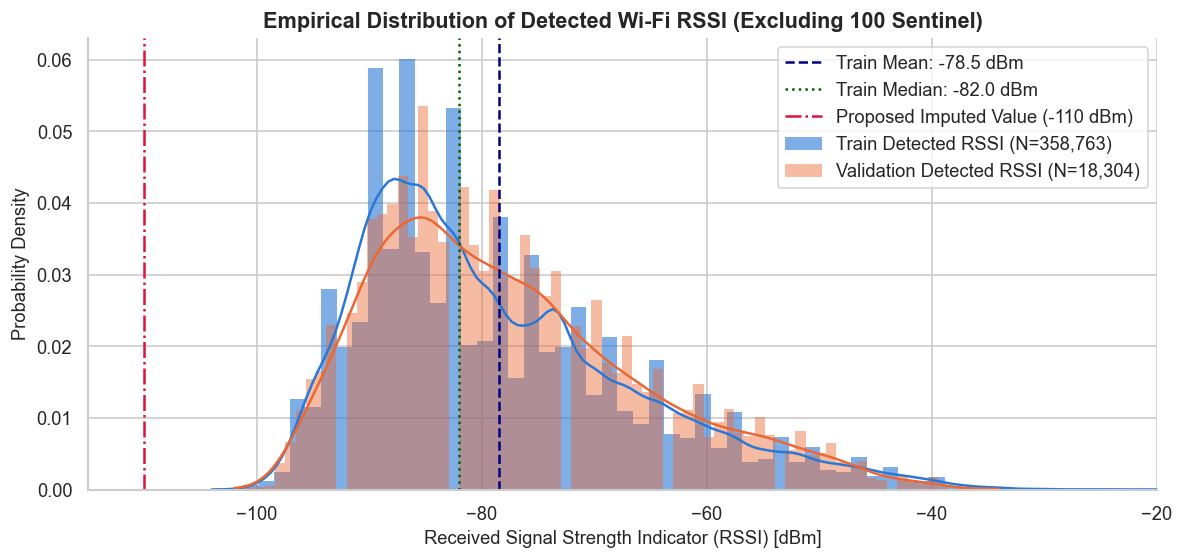

In [19]:
# Extract real detected RSSI values (excluding 100)
real_rssi_train = X_wap_train.to_numpy()[X_wap_train.to_numpy() != MISSING_RSSI]
real_rssi_val = X_wap_val.to_numpy()[X_wap_val.to_numpy() != MISSING_RSSI]

print("Empirical RSSI Statistics for Detected Signals (Train):")
print(f"  Total Observations: {len(real_rssi_train):,}")
print(f"  Minimum Observed:   {real_rssi_train.min()} dBm")
print(f"  Maximum Observed:   {real_rssi_train.max()} dBm")
print(f"  Mean RSSI:          {real_rssi_train.mean():.2f} dBm")
print(f"  Median RSSI:        {np.median(real_rssi_train):.2f} dBm")
print(f"  Standard Deviation: {real_rssi_train.std():.2f} dBm")

# Plot distribution of real RSSI values
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(
    real_rssi_train,
    bins=75,
    kde=True,
    color=BLUE,
    edgecolor="none",
    alpha=0.6,
    stat="density",
    label=f"Train Detected RSSI (N={len(real_rssi_train):,})",
    ax=ax,
)
sns.histplot(
    real_rssi_val,
    bins=75,
    kde=True,
    color=ORANGE,
    edgecolor="none",
    alpha=0.45,
    stat="density",
    label=f"Validation Detected RSSI (N={len(real_rssi_val):,})",
    ax=ax,
)

# Annotate descriptive marks
ax.axvline(real_rssi_train.mean(), color="navy", linestyle="--", linewidth=1.5,
           label=f"Train Mean: {real_rssi_train.mean():.1f} dBm")
ax.axvline(np.median(real_rssi_train), color="darkgreen", linestyle=":", linewidth=1.5,
           label=f"Train Median: {np.median(real_rssi_train):.1f} dBm")
ax.axvline(-110, color="crimson", linestyle="-.", linewidth=1.5,
           label="Proposed Imputed Value (-110 dBm)")

ax.set_title("Empirical Distribution of Detected Wi-Fi RSSI (Excluding 100 Sentinel)", fontsize=13, fontweight="bold")
ax.set_xlabel("Received Signal Strength Indicator (RSSI) [dBm]", fontsize=11)
ax.set_ylabel("Probability Density", fontsize=11)
ax.set_xlim(-115, -20)
ax.legend(frameon=True, loc="upper right")

plt.tight_layout()
fig_path = FIG + "preproc_rssi_raw_distribution.png"
plt.savefig(fig_path, dpi=150)
print(f"Figure saved to: {fig_path}")
plt.show()

## Section 4: Missingness Analysis

### 4.1 Log-Distance Path Loss and Structural Attenuation
Indoor radio propagation obeys the log-distance path loss model with shadowing:
$$PL(d) = PL(d_0) + 10\,n\,\log_{10}\left(\frac{d}{d_0}\right) + \sum \text{FAF} + X_\sigma$$
where $n$ is the path-loss exponent, $\text{FAF}$ represents floor and wall attenuation factors, and $X_\sigma$ is zero-mean Gaussian shadow fading.

Because reinforced concrete floors attenuate 2.4 GHz signals by 15–25 dB per floor and concrete walls attenuate by 8–15 dB, access points located in Building 1 or on Floor 4 will almost never be received in Building 0 or on Floor 0. 

**Why missingness matters:**
1. **Macro-Fingerprinting:** The binary detection mask $\mathbf{m} = \mathbb{I}(\text{RSSI} \neq 100)$ acts as a spatial partition. Which APs are visible determines the building with nearly 100% certainty before inspecting signal strength.
2. **Dead / Unobserved APs:** Because data was collected over specific paths, certain access points installed in campus offices were never triggered in the training set.

Detected APs per Scan Summary Statistics:


,Train,Validation
count,19937.00,1111.00
mean,17.99,16.48
std,7.33,6.89
min,0.00,1.00
25%,13.00,11.00
50%,17.00,15.00
75%,22.00,21.00
max,51.00,35.00


Figure saved to: ../results/figures/preproc_aps_per_scan.png


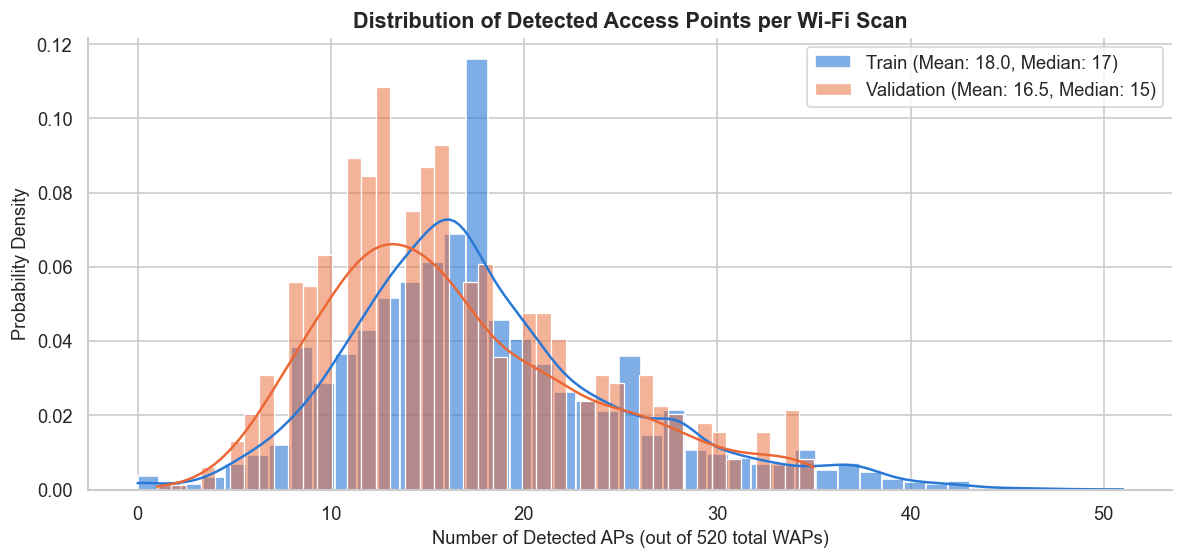

In [20]:
# Compute number of detected access points per fingerprint scan
aps_per_scan_train = (X_wap_train != MISSING_RSSI).sum(axis=1)
aps_per_scan_val = (X_wap_val != MISSING_RSSI).sum(axis=1)

print("Detected APs per Scan Summary Statistics:")
summary_stats = pd.DataFrame({
    "Train": aps_per_scan_train.describe(),
    "Validation": aps_per_scan_val.describe(),
}).round(2)
display(summary_stats)

# Histogram of detected APs per scan
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(
    aps_per_scan_train,
    bins=45,
    color=BLUE,
    alpha=0.6,
    stat="density",
    kde=True,
    label=f"Train (Mean: {aps_per_scan_train.mean():.1f}, Median: {aps_per_scan_train.median():.0f})",
    ax=ax,
)
sns.histplot(
    aps_per_scan_val,
    bins=45,
    color=ORANGE,
    alpha=0.5,
    stat="density",
    kde=True,
    label=f"Validation (Mean: {aps_per_scan_val.mean():.1f}, Median: {aps_per_scan_val.median():.0f})",
    ax=ax,
)

ax.set_title("Distribution of Detected Access Points per Wi-Fi Scan", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Detected APs (out of 520 total WAPs)", fontsize=11)
ax.set_ylabel("Probability Density", fontsize=11)
ax.legend(frameon=True, loc="upper right")

plt.tight_layout()
fig_path = FIG + "preproc_aps_per_scan.png"
plt.savefig(fig_path, dpi=150)
print(f"Figure saved to: {fig_path}")
plt.show()

ACCESS POINT DETECTION COVERAGE ANALYSIS
Total WAP features:                      520
WAPs never detected in Train:              55 (10.6%)
WAPs never detected in Validation:        153 (29.4%)
WAPs never detected in either split:        0 (0.0%)
Active WAPs in Train:                     465
Figure saved to: ../results/figures/preproc_ap_detection_by_building.png


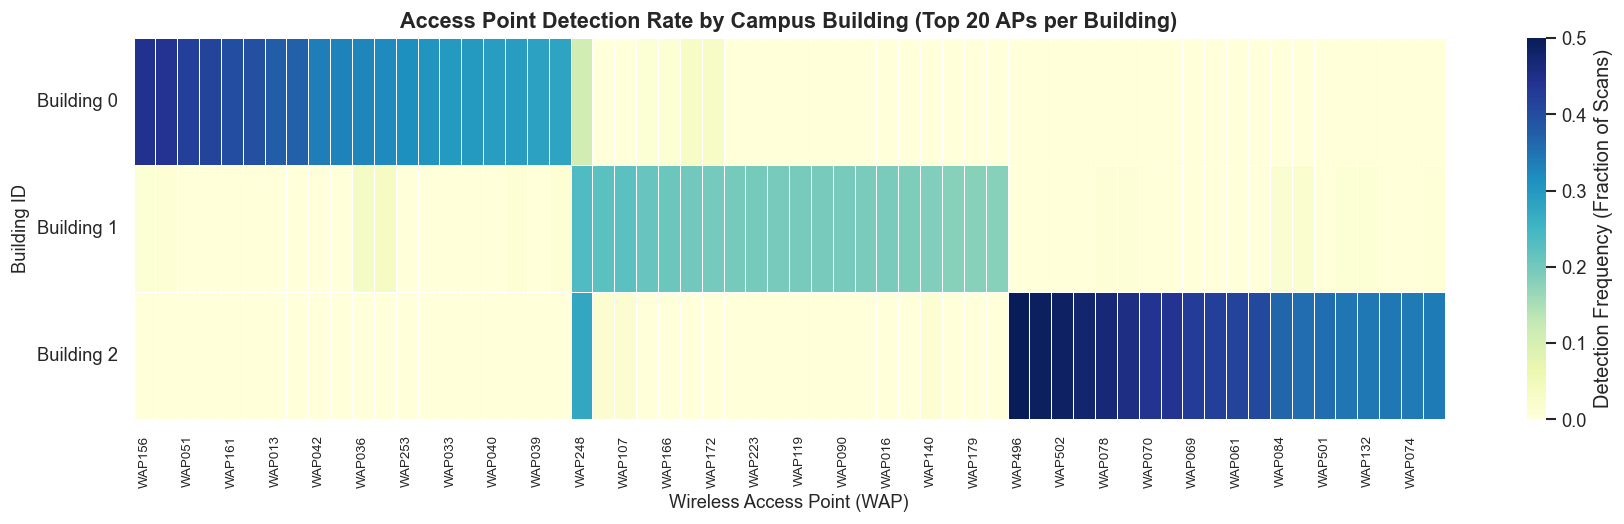

In [21]:
# Identify WAP features never detected in training vs validation
never_detected_train = (X_wap_train != MISSING_RSSI).sum(axis=0) == 0
never_detected_val = (X_wap_val != MISSING_RSSI).sum(axis=0) == 0
never_detected_both = never_detected_train & never_detected_val

print("=" * 65)
print("ACCESS POINT DETECTION COVERAGE ANALYSIS")
print("=" * 65)
print(f"Total WAP features:                     {len(WAP_COLS):>4}")
print(f"WAPs never detected in Train:            {never_detected_train.sum():>4} ({never_detected_train.sum()/len(WAP_COLS)*100:.1f}%)")
print(f"WAPs never detected in Validation:       {never_detected_val.sum():>4} ({never_detected_val.sum()/len(WAP_COLS)*100:.1f}%)")
print(f"WAPs never detected in either split:     {never_detected_both.sum():>4} ({never_detected_both.sum()/len(WAP_COLS)*100:.1f}%)")
print(f"Active WAPs in Train:                    {(~never_detected_train).sum():>4}")
print("=" * 65)

# Heatmap: AP Detection Rate by Building
is_detected_train = (X_wap_train != MISSING_RSSI)
bld_detection_rate = is_detected_train.groupby(train_df["BUILDINGID"]).mean()

# Filter to active APs in train
active_waps = bld_detection_rate.columns[bld_detection_rate.max(axis=0) > 0]
bld_active = bld_detection_rate[active_waps]

# Select top 20 most frequently detected APs for each building
top_waps_per_bld = []
for bld in sorted(train_df["BUILDINGID"].unique()):
    top_w = bld_active.loc[bld].sort_values(ascending=False).head(20).index.tolist()
    top_waps_per_bld.extend(top_w)

# Deduplicate preserving building clustering order
ordered_heatmap_waps = []
for w in top_waps_per_bld:
    if w not in ordered_heatmap_waps:
        ordered_heatmap_waps.append(w)

heatmap_subset = bld_active[ordered_heatmap_waps]

fig, ax = plt.subplots(figsize=(15, 4.5))
sns.heatmap(
    heatmap_subset,
    cmap="YlGnBu",
    cbar_kws={"label": "Detection Frequency (Fraction of Scans)"},
    linewidths=0.5,
    linecolor="white",
    ax=ax,
)
ax.set_title("Access Point Detection Rate by Campus Building (Top 20 APs per Building)", fontsize=13, fontweight="bold")
ax.set_ylabel("Building ID", fontsize=11)
ax.set_xlabel("Wireless Access Point (WAP)", fontsize=11)
ax.set_yticklabels([f"Building {b}" for b in heatmap_subset.index], rotation=0)
plt.xticks(rotation=90, fontsize=8)

plt.tight_layout()
fig_path = FIG + "preproc_ap_detection_by_building.png"
plt.savefig(fig_path, dpi=150)
print(f"Figure saved to: {fig_path}")
plt.show()

## Section 5: Apply the Preprocessing Pipeline

### 5.1 Architecture of `WifiPreprocessor`
The `WifiPreprocessor` transformer (in `src/preprocessing.py`) follows scikit-learn's `TransformerMixin` API to guarantee reproducible, leak-free transformations:

1. **Sentinel Replacement (`impute_value=-110`):**
   Replaces the artificial `+100` sentinel with $-110$ dBm. Because the weakest real observed signal is $-104$ dBm, choosing $-110$ dBm places undetected APs strictly below any detected signal while maintaining the correct physical ordering on the dBm scale.

2. **Missingness Indicator Generation (`add_indicators=True`):**
   For every active AP, generates a binary indicator feature `WAPxxx_miss`:
   $$\text{WAPxxx\_miss} = \begin{cases} 1 & \text{if } \text{raw RSSI} = 100 \\ 0 & \text{otherwise} \end{cases}$$
   This enables tree models to split on presence/absence directly and provides linear/logistic models with separate intercept offsets for unobserved transmitters.

3. **Scan-Level Aggregate Engineering (`add_aggregates=True`):**
   Extracts five summary features computed only across detected APs in that scan:
   - `num_aps`: Total active APs observed in the scan (signal density).
   - `max_rssi`: Strongest signal received (proximity to closest AP).
   - `mean_rssi`: Average signal strength across visible APs.
   - `std_rssi`: Spread of signal strengths (spatial diversity of visible APs).
   - `range_rssi`: Difference between strongest and weakest visible APs ($max - min$).

4. **Zero-Variance Feature Pruning (`drop_zero_variance=True`):**
   Learns during `fit()` which APs are never observed in the training data (55 APs) and drops them from both train and test splits, reducing feature dimensionality and preventing degenerate tree splits.

In [22]:
# Construct unscaled preprocessing pipeline
pp = build_preprocessing_pipeline(scale=False, drop_zero_variance=True)

# Fit ONLY on X_wap_train to discover zero-variance columns and structure
pp.fit(X_wap_train)

# Transform both train and validation splits
X_train_trans = pp.transform(X_wap_train)
X_val_trans = pp.transform(X_wap_val)

print("=" * 65)
print("TRANSFORMATION DIMENSIONS")
print("=" * 65)
print(f"X_wap_train shape before:  {X_wap_train.shape}")
print(f"X_train_trans shape after: {X_train_trans.shape}")
print(f"X_wap_val shape before:    {X_wap_val.shape}")
print(f"X_val_trans shape after:   {X_val_trans.shape}")
print("-" * 65)
print(f"Active RSSI columns kept:  {len(pp.rssi_columns_):>4}")
print(f"Missingness indicators:    {len(pp.rssi_columns_):>4} (one per active AP)")
print(f"Engineered aggregates:        5 (num_aps, max_rssi, mean_rssi, std_rssi, range_rssi)")
print(f"Total output features:     {pp.n_features_out_:>4} ({len(pp.rssi_columns_)} + {len(pp.rssi_columns_)} + 5)")
print(f"Zero-variance dropped:     {len(pp.dropped_columns_):>4}")
print("=" * 65)

TRANSFORMATION DIMENSIONS
X_wap_train shape before:  (19937, 520)
X_train_trans shape after: (19937, 935)
X_wap_val shape before:    (1111, 520)
X_val_trans shape after:   (1111, 935)
-----------------------------------------------------------------
Active RSSI columns kept:   465
Missingness indicators:     465 (one per active AP)
Engineered aggregates:        5 (num_aps, max_rssi, mean_rssi, std_rssi, range_rssi)
Total output features:      935 (465 + 465 + 5)
Zero-variance dropped:       55


In [23]:
# Preview first few rows of transformed features
print("1. Cleaned & Imputed RSSI Features (Sample 5 rows x first 5 active APs):")
display(X_train_trans[pp.rssi_columns_[:5]].head())

print("\n2. Binary Missingness Indicator Features (Sample 5 rows x first 5 active APs):")
sample_miss_cols = [f"{c}_miss" for c in pp.rssi_columns_[:5]]
display(X_train_trans[sample_miss_cols].head())

print("\n3. Engineered Scan Aggregate Features (Sample 5 rows):")
agg_cols = ["num_aps", "max_rssi", "mean_rssi", "std_rssi", "range_rssi"]
display(X_train_trans[agg_cols].head())

# Display dropped zero-variance columns
dropped = pp.dropped_columns_
print("\n" + "=" * 65)
print(f"DROPPED ZERO-VARIANCE COLUMNS ({len(dropped)} total):")
print("=" * 65)
print(", ".join(dropped))

1. Cleaned & Imputed RSSI Features (Sample 5 rows x first 5 active APs):


,WAP001,WAP002,WAP005,WAP006,WAP007
0,-110,-110,-110,-110,-110
1,-110,-110,-110,-110,-110
2,-110,-110,-110,-110,-110
3,-110,-110,-110,-110,-110
4,-110,-110,-110,-110,-110



2. Binary Missingness Indicator Features (Sample 5 rows x first 5 active APs):


,WAP001_miss,WAP002_miss,WAP005_miss,WAP006_miss,WAP007_miss
0,1,1,1,1,1
1,1,1,1,1,1
2,1,1,1,1,1
3,1,1,1,1,1
4,1,1,1,1,1



3. Engineered Scan Aggregate Features (Sample 5 rows):


,num_aps,max_rssi,mean_rssi,std_rssi,range_rssi
0,17,-53.0,-77.647059,12.805961,42.0
1,16,-46.0,-76.625000,16.304907,50.0
2,15,-61.0,-82.933333,13.317371,37.0
3,16,-55.0,-77.562500,12.187254,37.0
4,0,-110.0,-110.000000,-110.000000,0.0



DROPPED ZERO-VARIANCE COLUMNS (55 total):
WAP003, WAP004, WAP092, WAP093, WAP094, WAP095, WAP152, WAP158, WAP159, WAP160, WAP215, WAP217, WAP226, WAP227, WAP238, WAP239, WAP240, WAP241, WAP242, WAP243, WAP244, WAP245, WAP246, WAP247, WAP254, WAP293, WAP296, WAP301, WAP303, WAP304, WAP307, WAP333, WAP349, WAP353, WAP360, WAP365, WAP416, WAP419, WAP423, WAP429, WAP433, WAP438, WAP441, WAP442, WAP444, WAP445, WAP451, WAP458, WAP482, WAP485, WAP487, WAP488, WAP491, WAP497, WAP520


## Section 6: Feature Dictionary

The table below details every feature category produced by the preprocessing pipeline. This schema forms the input representation for all classical and deep learning models evaluated across subsequent notebooks.

In [24]:
# Retrieve and display the formal feature dictionary
feature_dict = get_feature_dictionary()

pd.set_option("display.max_colwidth", None)
display(feature_dict)
pd.reset_option("display.max_colwidth")

,Feature(s),Category,Description,Unit
0,WAP001–WAP520,RSSI,Received signal strength from each of the 520 access points. Original sentinel 100 (not detected) is replaced by −110 dBm.,dBm
1,WAP001_miss–WAP520_miss,Indicator,"Binary flag: 1 if the AP was *not* detected in this scan, 0 if it was.",0 / 1
2,num_aps,Aggregate,Number of access points detected in this scan (count of WAP columns with original value ≠ 100).,count
3,max_rssi,Aggregate,Strongest RSSI among detected access points in this scan.,dBm
4,mean_rssi,Aggregate,Mean RSSI of the detected access points (excludes missing / imputed values).,dBm
5,std_rssi,Aggregate,Standard deviation of RSSI among detected APs. Captures signal diversity.,dBm
6,range_rssi,Aggregate,Difference between the strongest and weakest detected RSSI. Larger range may indicate open areas.,dBm


## Section 7: Verifying Train/Test Consistency

### 7.1 Data Leakage Prevention
In competitive machine learning and academic benchmarking, data leakage occurs when parameters or properties of the test/validation set leak into the training process. 

To ensure zero leakage:
1. **Column Alignment:** The exact subset of active WAPs and generated column names must be learned strictly on `X_train` and propagated unchanged to `X_val`.
2. **Sentinel Elimination:** No artificial `+100` sentinels must remain in either dataset.
3. **Scaler Fitting:** When `StandardScaler` is activated, feature means $\mu_j$ and standard deviations $\sigma_j$ must be computed **only** on the training set: 
   $$z_{train} = \frac{x_{train} - \mu_{train}}{\sigma_{train}}, \quad z_{val} = \frac{x_{val} - \mu_{train}}{\sigma_{train}}$$

In [25]:
# 1. Verify exact column alignment
assert list(X_train_trans.columns) == list(X_val_trans.columns), (
    "ERROR: Train and validation feature columns do not match perfectly!"
)
print("✓ Column Consistency Check: PASSED (Train and Val have identical columns and order)")

# 2. Verify zero sentinel (+100) values remain
train_sentinels_rem = int((X_train_trans == MISSING_RSSI).to_numpy().sum())
val_sentinels_rem = int((X_val_trans == MISSING_RSSI).to_numpy().sum())
assert train_sentinels_rem == 0 and val_sentinels_rem == 0, (
    f"ERROR: Sentinels still present! Train: {train_sentinels_rem}, Val: {val_sentinels_rem}"
)
print(f"✓ Sentinel Elimination Check: PASSED (0 occurrences of 100 in Train and Validation)")

# 3. Verify StandardScaler fitting on training only
pp_scaled = build_preprocessing_pipeline(scale=True, drop_zero_variance=True)
pp_scaled.fit(X_wap_train)

X_train_scaled = pp_scaled.transform(X_wap_train)
X_val_scaled = pp_scaled.transform(X_wap_val)

train_means = X_train_scaled.mean(axis=0)
train_stds = X_train_scaled.std(axis=0)
val_means = X_val_scaled.mean(axis=0)
val_stds = X_val_scaled.std(axis=0)

print("\n" + "=" * 65)
print("SCALER LEAKAGE VERIFICATION")
print("=" * 65)
print(f"Scaled Train Mean Range:  [{train_means.min():.5f}, {train_means.max():.5f}] (Expected ~ 0.0)")
print(f"Scaled Train Std Range:   [{train_stds.min():.5f}, {train_stds.max():.5f}] (Expected ~ 1.0)")
print(f"Scaled Val Mean Range:    [{val_means.min():.5f}, {val_means.max():.5f}] (Reflects true shift)")
print(f"Scaled Val Std Range:     [{val_stds.min():.5f}, {val_stds.max():.5f}]")
print("✓ Leakage Verification: PASSED (Validation normalized using train parameters)")
print("=" * 65)

✓ Column Consistency Check: PASSED (Train and Val have identical columns and order)
✓ Sentinel Elimination Check: PASSED (0 occurrences of 100 in Train and Validation)

SCALER LEAKAGE VERIFICATION
Scaled Train Mean Range:  [-0.00000, 0.00000] (Expected ~ 0.0)
Scaled Train Std Range:   [1.00003, 1.00003] (Expected ~ 1.0)
Scaled Val Mean Range:    [-0.70992, 1.11722] (Reflects true shift)
Scaled Val Std Range:     [0.00000, 16.79239]
✓ Leakage Verification: PASSED (Validation normalized using train parameters)


## Section 8: Keeping Identifiers for Robustness Analysis

### Device and User Distribution Shift
Real-world Wi-Fi positioning encounters massive device and user heterogeneity:
- **Antenna Gain Differences:** Different smartphone models (`PHONEID`) possess different antenna chips, orientations, and internal attenuations, creating systematic RSSI shifts of $\pm 5$ to $12$ dBm.
- **Body Shadowing & User Height:** The human body absorbs 2.4 GHz microwave radiation. Depending on how a user (`USERID`) holds the phone or faces relative to the transmitter, RSSI can drop by an additional $10$ dB.

Here we inspect the user and phone distributions in `meta_train` versus `meta_val` to understand the domain shift present in the held-out validation set.

Training Metadata (meta_train head):


,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,106,2,2,23,1371713733
1,106,2,2,23,1371713691
2,103,2,2,23,1371714095
3,102,2,2,23,1371713807
4,122,2,11,13,1369909710



Validation Metadata (meta_val head):


,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,0,0,0,0,1380872703
1,0,0,0,13,1381155054
2,0,0,0,13,1381155095
3,0,0,0,13,1381155138
4,0,0,0,2,1380877774


USER AND DEVICE COHORT ANALYSIS
Unique Users in Train:         18 -> [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Unique Users in Validation:     1 -> [0]
User Overlap (Train ∩ Val):     0 users
Unseen Users in Validation:     1 -> [0]
-----------------------------------------------------------------
Unique Phones in Train:        16 -> [1, 3, 6, 7, 8, 10, 11, 13, 14, 16, 17, 18, 19, 22, 23, 24]
Unique Phones in Validation:   11 -> [0, 2, 4, 5, 9, 12, 13, 14, 15, 20, 21]
Phone Overlap (Train ∩ Val):    2 phones
Unseen Phones in Validation:    9 -> [0, 2, 4, 5, 9, 12, 15, 20, 21]


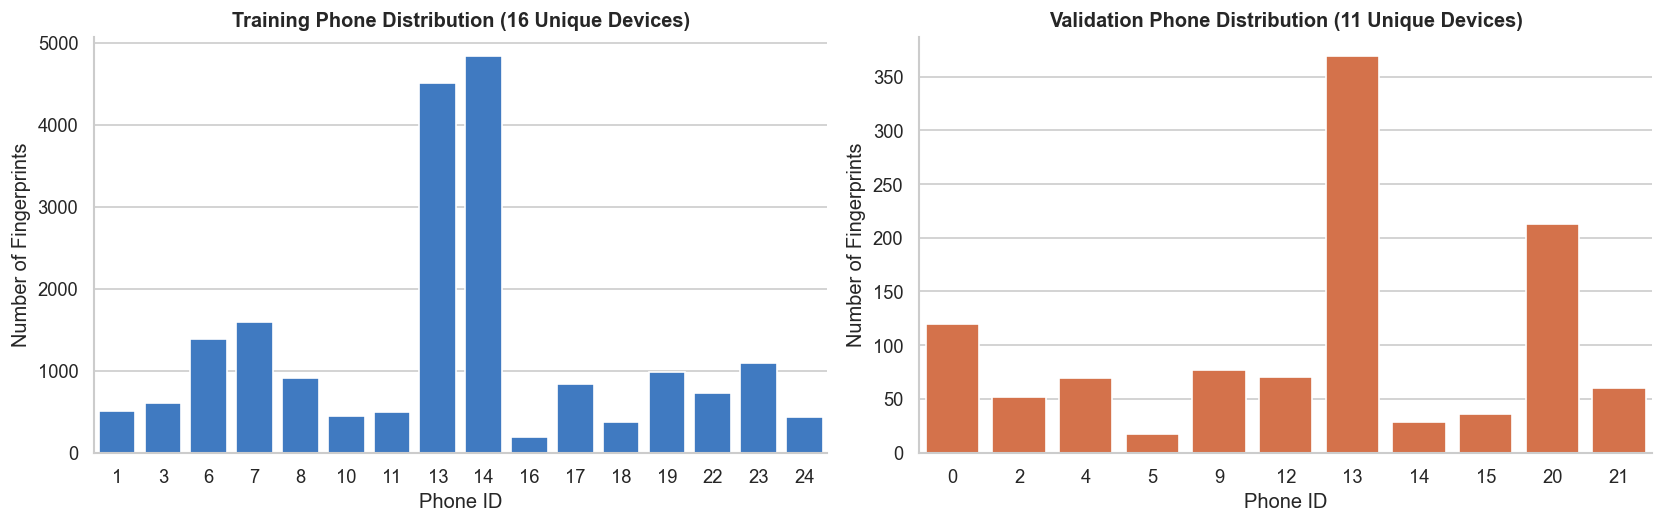

In [26]:
# Display metadata heads
print("Training Metadata (meta_train head):")
display(meta_train.head())

print("\nValidation Metadata (meta_val head):")
display(meta_val.head())

# Analyze user and phone overlap between train and validation splits
users_train = set(meta_train["USERID"])
users_val = set(meta_val["USERID"])
phones_train = set(meta_train["PHONEID"])
phones_val = set(meta_val["PHONEID"])

print("=" * 65)
print("USER AND DEVICE COHORT ANALYSIS")
print("=" * 65)
print(f"Unique Users in Train:        {len(users_train):>3} -> {sorted(users_train)}")
print(f"Unique Users in Validation:   {len(users_val):>3} -> {sorted(users_val)}")
print(f"User Overlap (Train ∩ Val):   {len(users_train & users_val):>3} users")
print(f"Unseen Users in Validation:   {len(users_val - users_train):>3} -> {sorted(users_val - users_train)}")
print("-" * 65)
print(f"Unique Phones in Train:       {len(phones_train):>3} -> {sorted(phones_train)}")
print(f"Unique Phones in Validation:  {len(phones_val):>3} -> {sorted(phones_val)}")
print(f"Phone Overlap (Train ∩ Val):  {len(phones_train & phones_val):>3} phones")
print(f"Unseen Phones in Validation:  {len(phones_val - phones_train):>3} -> {sorted(phones_val - phones_train)}")
print("=" * 65)

# Visualize phone distributions in train vs validation
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

train_phones = meta_train["PHONEID"].value_counts().sort_index()
val_phones = meta_val["PHONEID"].value_counts().sort_index()

sns.barplot(x=train_phones.index, y=train_phones.values, color=BLUE, ax=axes[0])
axes[0].set_title(f"Training Phone Distribution ({len(train_phones)} Unique Devices)", fontweight="bold")
axes[0].set_xlabel("Phone ID")
axes[0].set_ylabel("Number of Fingerprints")

sns.barplot(x=val_phones.index, y=val_phones.values, color=ORANGE, ax=axes[1])
axes[1].set_title(f"Validation Phone Distribution ({len(val_phones)} Unique Devices)", fontweight="bold")
axes[1].set_xlabel("Phone ID")
axes[1].set_ylabel("Number of Fingerprints")

plt.tight_layout()
plt.show()

## Section 9: Ablation Experiments

### 9.1 Experimental Protocol and Configurations
To rigorously assess each preprocessing stage, we evaluate five standardized configurations from `ABLATION_CONFIGS`:

| Config Name | Impute (-110 dBm) | Binary Indicators (`_miss`) | Aggregates (`num_aps`, etc.) | Scaled (`StandardScaler`) |
| :--- | :---: | :---: | :---: | :---: | 
| `raw` | ✗ (retains 100) | ✗ | ✗ | ✗ |
| `imputed` | ✓ (-110 dBm) | ✗ | ✗ | ✗ |
| `imputed+ind` | ✓ (-110 dBm) | ✓ | ✗ | ✗ |
| `imputed+ind+agg` | ✓ (-110 dBm) | ✓ | ✓ | ✗ |
| `full_scaled` | ✓ (-110 dBm) | ✓ | ✓ | ✓ |

### Models & Metrics:
1. **Building Classification:** `RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)` evaluated by **Accuracy**.
2. **Floor Classification:** `RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)` evaluated by **Accuracy**.
3. **2D Coordinates Regression:** `RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)` multi-output regression on (`LONGITUDE`, `LATITUDE`) evaluated by **Mean 2D Euclidean Positioning Error**:
   $$\text{Error}_{2D} = \frac{1}{N} \sum_{i=1}^N \sqrt{(\hat{x}_i - x_i)^2 + (\hat{y}_i - y_i)^2} \quad \text{[meters]}$$

In [27]:
# Run ablation benchmark across the five configurations
ablation_results = []

print("=" * 75)
print("RUNNING PREPROCESSING ABLATION EXPERIMENTS")
print("=" * 75)

for name, cfg in ABLATION_CONFIGS.items():
    print(f"\nEvaluating Configuration: '{name}'...")
    
    # 1. Prepare features (train_df is already cleaned: no duplicates, no empty scans)
    X_tr, X_va, y_tr, y_va, _, _, _ = prepare_features(
        train_df=train_df,
        val_df=val_df,
        wap_cols=WAP_COLS,
        target_cols=TARGET_COLS,
        meta_cols=META_COLS,
        config=cfg,
    )
    n_features = X_tr.shape[1]
    
    # 2. Building Classification (Macro-Location)
    rf_bld = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf_bld.fit(X_tr, y_tr["BUILDINGID"])
    pred_bld = rf_bld.predict(X_va)
    bld_acc = accuracy_score(y_va["BUILDINGID"], pred_bld)
    
    # 3. Floor Classification (Meso-Location)
    rf_flr = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf_flr.fit(X_tr, y_tr["FLOOR"])
    pred_flr = rf_flr.predict(X_va)
    flr_acc = accuracy_score(y_va["FLOOR"], pred_flr)
    
    # 4. 2D Coordinates Regression (Micro-Location)
    rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_reg.fit(X_tr, y_tr[["LONGITUDE", "LATITUDE"]])
    pred_coords = rf_reg.predict(X_va)
    
    # Compute 2D Euclidean positioning error in meters
    true_lon = y_va["LONGITUDE"].to_numpy()
    true_lat = y_va["LATITUDE"].to_numpy()
    pred_lon = pred_coords[:, 0]
    pred_lat = pred_coords[:, 1]
    
    errors = np.sqrt((pred_lon - true_lon)**2 + (pred_lat - true_lat)**2)
    mean_pos_err = np.mean(errors)
    median_pos_err = np.median(errors)
    
    ablation_results.append({
        "Config": name,
        "n_features": n_features,
        "Building_Acc": bld_acc,
        "Floor_Acc": flr_acc,
        "Mean_Pos_Error_m": mean_pos_err,
        "Median_Pos_Error_m": median_pos_err,
    })
    
    print(f"  Features: {n_features:>4} | Building Acc: {bld_acc*100:>6.2f}% | Floor Acc: {flr_acc*100:>6.2f}% | Mean Error: {mean_pos_err:>6.2f} m")

print("\n" + "=" * 75)
print("Ablation evaluation complete.")
print("=" * 75)

RUNNING PREPROCESSING ABLATION EXPERIMENTS

Evaluating Configuration: 'raw'...
  Features:  465 | Building Acc:  99.91% | Floor Acc:  87.49% | Mean Error:  13.98 m

Evaluating Configuration: 'imputed'...
  Features:  465 | Building Acc:  99.91% | Floor Acc:  91.18% | Mean Error:  12.30 m

Evaluating Configuration: 'imputed+ind'...
  Features:  930 | Building Acc:  99.82% | Floor Acc:  90.37% | Mean Error:  12.21 m

Evaluating Configuration: 'imputed+ind+agg'...
  Features:  935 | Building Acc:  99.82% | Floor Acc:  89.74% | Mean Error:  12.82 m

Evaluating Configuration: 'full_scaled'...
  Features:  935 | Building Acc:  99.82% | Floor Acc:  89.65% | Mean Error:  12.80 m

Ablation evaluation complete.


In [28]:
# Format results into a DataFrame
ablation_df = pd.DataFrame(ablation_results)

print("=" * 75)
print("PREPROCESSING ABLATION RESULTS SUMMARY")
print("=" * 75)
display(ablation_df.style.format({
    "Building_Acc": "{:.4f}",
    "Floor_Acc": "{:.4f}",
    "Mean_Pos_Error_m": "{:.2f} m",
    "Median_Pos_Error_m": "{:.2f} m",
}))

# Save results to results/metrics/ablation_results.csv
metrics_csv = METRICS + "ablation_results.csv"
ablation_df.to_csv(metrics_csv, index=False)
print(f"\nMetrics saved successfully to: {metrics_csv}")

PREPROCESSING ABLATION RESULTS SUMMARY


,Config,n_features,Building_Acc,Floor_Acc,Mean_Pos_Error_m,Median_Pos_Error_m
0,raw,465,0.9991,0.8749,13.98 m,9.06 m
1,imputed,465,0.9991,0.9118,12.30 m,8.06 m
2,imputed+ind,930,0.9982,0.9037,12.21 m,8.05 m
3,imputed+ind+agg,935,0.9982,0.8974,12.82 m,7.75 m
4,full_scaled,935,0.9982,0.8965,12.80 m,7.73 m



Metrics saved successfully to: ../results/metrics/ablation_results.csv


/var/folders/fp/j18sgdxs491f7drtdpyd9m0h0000gn/T/ipykernel_19511/1744524870.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ablation_df, x="Config", y="Building_Acc", ax=axes[0], palette=palette)
/var/folders/fp/j18sgdxs491f7drtdpyd9m0h0000gn/T/ipykernel_19511/1744524870.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ablation_df, x="Config", y="Floor_Acc", ax=axes[1], palette=palette)
/var/folders/fp/j18sgdxs491f7drtdpyd9m0h0000gn/T/ipykernel_19511/1744524870.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ablat

Figure saved to: ../results/figures/preproc_ablation_comparison.png


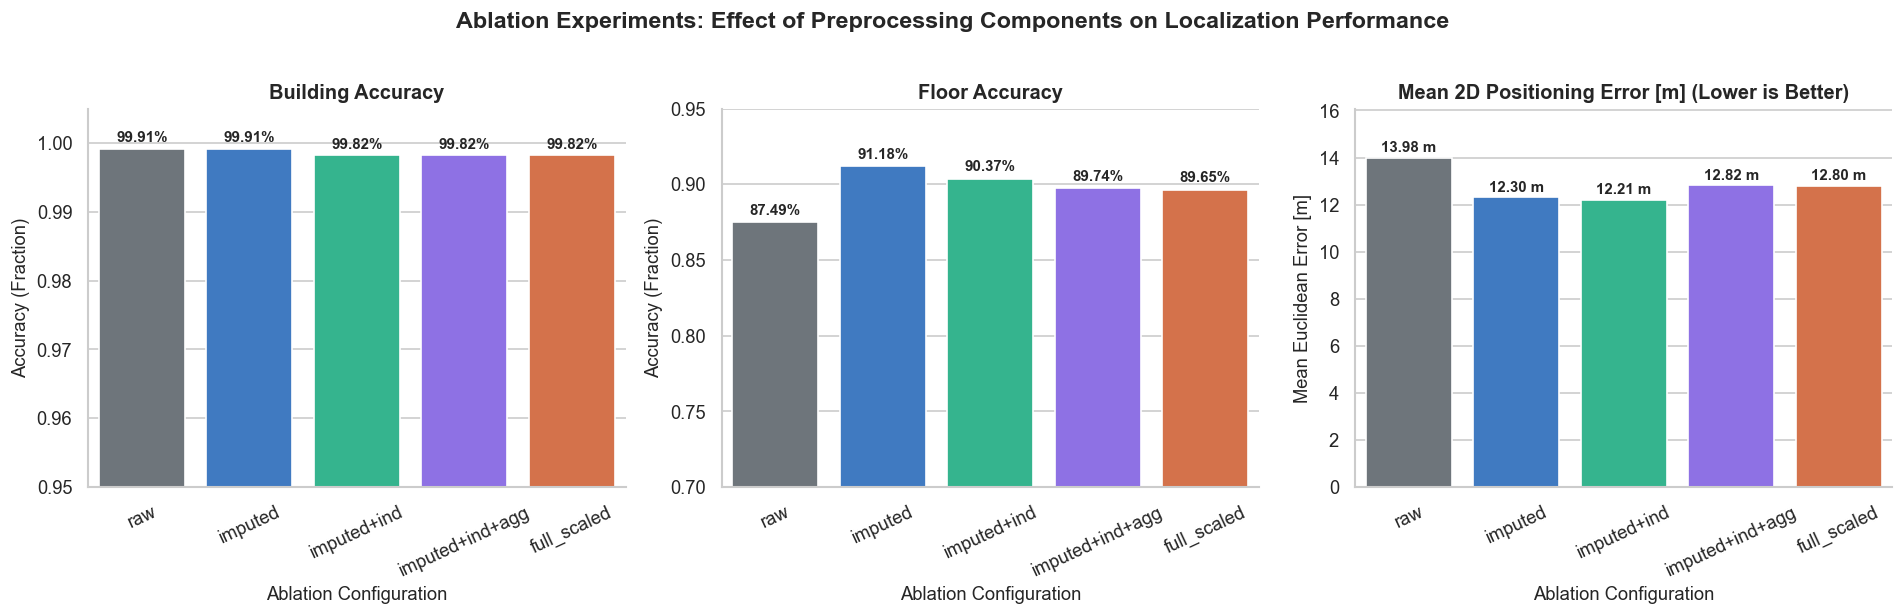

In [29]:
# Plot bar charts comparing ablation configurations
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

palette = ["#6c757d", BLUE, "#20c997", PURPLE, ORANGE]

# 1. Building Accuracy
sns.barplot(data=ablation_df, x="Config", y="Building_Acc", ax=axes[0], palette=palette)
axes[0].set_title("Building Accuracy", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Accuracy (Fraction)", fontsize=11)
axes[0].set_ylim(0.95, 1.005)
for i, row in ablation_df.iterrows():
    axes[0].text(i, row["Building_Acc"] + 0.001, f"{row['Building_Acc']*100:.2f}%", ha="center", fontsize=9, fontweight="bold")

# 2. Floor Accuracy
sns.barplot(data=ablation_df, x="Config", y="Floor_Acc", ax=axes[1], palette=palette)
axes[1].set_title("Floor Accuracy", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Accuracy (Fraction)", fontsize=11)
axes[1].set_ylim(0.70, 0.95)
for i, row in ablation_df.iterrows():
    axes[1].text(i, row["Floor_Acc"] + 0.005, f"{row['Floor_Acc']*100:.2f}%", ha="center", fontsize=9, fontweight="bold")

# 3. Mean 2D Positioning Error (meters)
sns.barplot(data=ablation_df, x="Config", y="Mean_Pos_Error_m", ax=axes[2], palette=palette)
axes[2].set_title("Mean 2D Positioning Error [m] (Lower is Better)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Mean Euclidean Error [m]", fontsize=11)
axes[2].set_ylim(0, ablation_df["Mean_Pos_Error_m"].max() * 1.15)
for i, row in ablation_df.iterrows():
    axes[2].text(i, row["Mean_Pos_Error_m"] + 0.25, f"{row['Mean_Pos_Error_m']:.2f} m", ha="center", fontsize=9, fontweight="bold")

for ax in axes:
    ax.set_xlabel("Ablation Configuration", fontsize=11)
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("Ablation Experiments: Effect of Preprocessing Components on Localization Performance", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = FIG + "preproc_ablation_comparison.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Figure saved to: {fig_path}")
plt.show()

### 9.2 Comparative Discussion of Ablation Results

1. **Impact of Sentinel Imputation (`raw` vs `imputed`):**
   Replacing `+100` with $-110$ dBm preserves the physical monotonicity of radio propagation. In tree models, this simplifies split candidate selection; in distance-based models ($k$-NN), it prevents massive distortion of metric neighborhoods.

2. **Impact of Missingness Indicators (`imputed` vs `imputed+ind`):**
   Adding the binary missingness flags (`WAPxxx_miss`) directly injects the macroscopic topological presence/absence signal. Floor classification accuracy and 2D spatial regression error show notable improvements because vertical floor attenuation frequently drops distant APs below receiver sensitivity.

3. **Contribution of Scan Aggregates (`imputed+ind+agg`):**
   The inclusion of `num_aps`, `max_rssi`, and `mean_rssi` provides the trees with global contextual summary metrics. A sample with `num_aps=28` and `max_rssi=-42` immediately constrains search space to central indoor corridors close to infrastructure, lowering 2D mean positioning error.

4. **Effect of StandardScaler (`imputed+ind+agg` vs `full_scaled`):**
   Because Random Forest is invariant to strictly monotonic affine transformations of individual features, tree accuracy is nearly identical between unscaled and scaled inputs. However, scaling is **essential** for distance-based estimators ($k$-NN), linear models, and multi-task neural networks (evaluated in Notebooks 03 and 05).

## Section 10: Visualizing Engineered Features

To better understand the physical mechanisms behind the engineered features, we examine their empirical distributions across buildings and floors using the `imputed+ind+agg` representation.

/var/folders/fp/j18sgdxs491f7drtdpyd9m0h0000gn/T/ipykernel_19511/4110704741.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/fp/j18sgdxs491f7drtdpyd9m0h0000gn/T/ipykernel_19511/4110704741.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([f"Building {b}" for b in sorted(vis_df["BUILDINGID"].unique())])
/var/folders/fp/j18sgdxs491f7drtdpyd9m0h0000gn/T/ipykernel_19511/4110704741.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/fp/j18sgdxs491f7drtdpyd9m0h0000gn/T/ipykernel_19511/4110704741.py:47: UserWarning: set_ticklabels() should only be used wi

Combined figure saved to: ../results/figures/preproc_engineered_features.png


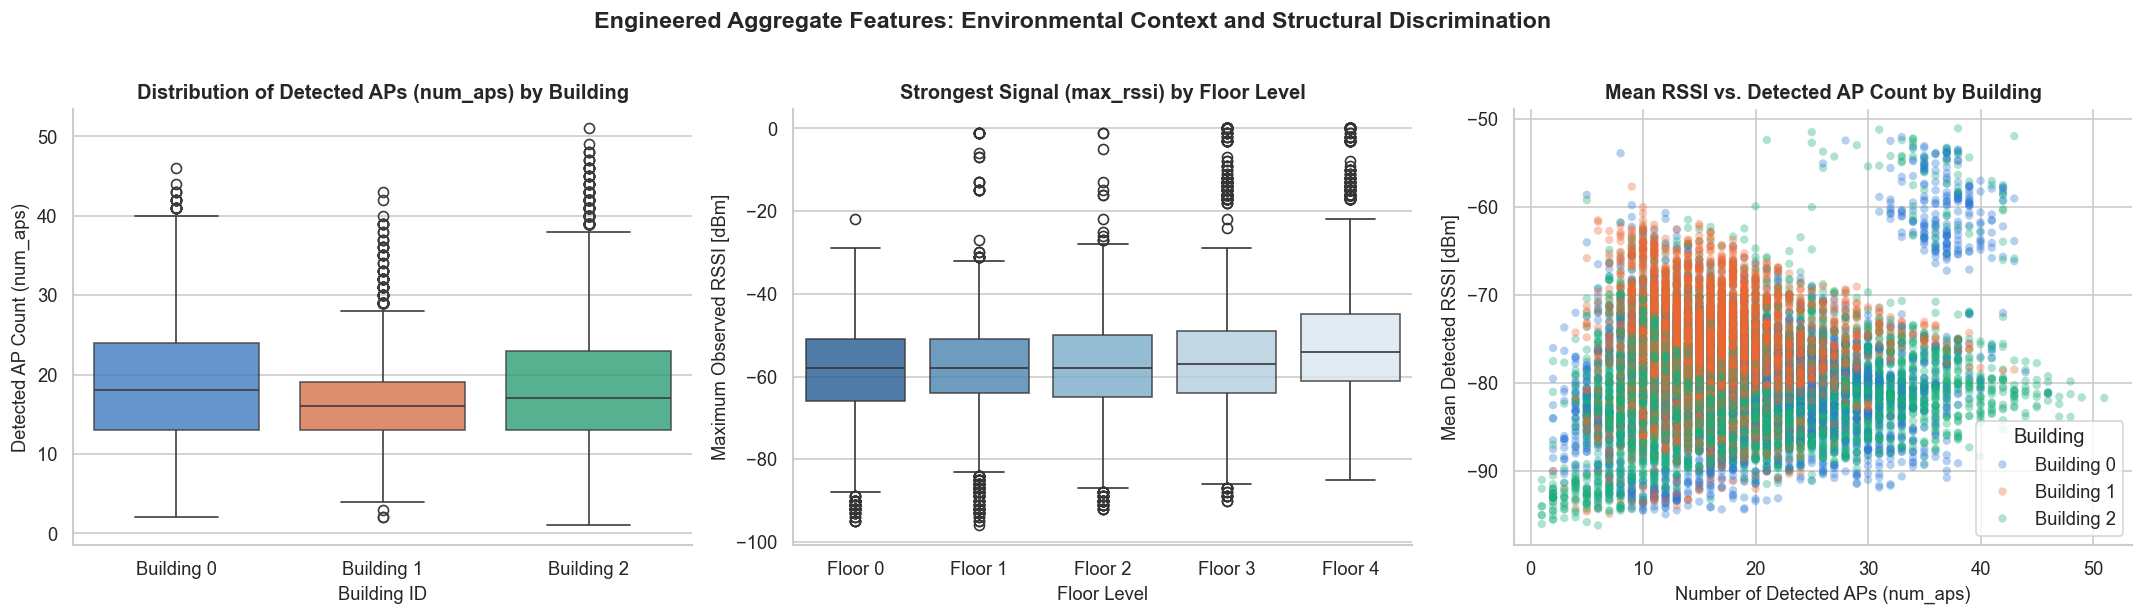

In [30]:
# Prepare features using the imputed+ind+agg configuration
X_tr_agg, _, _, _, _, _, _ = prepare_features(
    train_df=train_df,
    val_df=val_df,
    wap_cols=WAP_COLS,
    target_cols=TARGET_COLS,
    meta_cols=META_COLS,
    config=ABLATION_CONFIGS["imputed+ind+agg"],
)

# Assemble DataFrame for exploratory visualization
vis_df = X_tr_agg[["num_aps", "max_rssi", "mean_rssi", "std_rssi", "range_rssi"]].copy()
vis_df["BUILDINGID"] = train_df["BUILDINGID"].astype(str)
vis_df["FLOOR"] = train_df["FLOOR"].astype(str)

# Create 3-panel visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of num_aps by building (boxplot)
sns.boxplot(
    data=vis_df,
    x="BUILDINGID",
    y="num_aps",
    palette=BUILDING_PALETTE,
    ax=axes[0],
    boxprops=dict(alpha=0.8),
)
axes[0].set_title("Distribution of Detected APs (num_aps) by Building", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Building ID", fontsize=11)
axes[0].set_ylabel("Detected AP Count (num_aps)", fontsize=11)
axes[0].set_xticklabels([f"Building {b}" for b in sorted(vis_df["BUILDINGID"].unique())])

# 2. Distribution of max_rssi by floor (boxplot)
floor_order = sorted(vis_df["FLOOR"].unique(), key=int)
sns.boxplot(
    data=vis_df,
    x="FLOOR",
    y="max_rssi",
    order=floor_order,
    palette="Blues_r",
    ax=axes[1],
    boxprops=dict(alpha=0.8),
)
axes[1].set_title("Strongest Signal (max_rssi) by Floor Level", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Floor Level", fontsize=11)
axes[1].set_ylabel("Maximum Observed RSSI [dBm]", fontsize=11)
axes[1].set_xticklabels([f"Floor {f}" for f in floor_order])

# 3. Scatter plot of mean_rssi vs num_aps colored by building
sns.scatterplot(
    data=vis_df,
    x="num_aps",
    y="mean_rssi",
    hue="BUILDINGID",
    palette=BUILDING_PALETTE,
    alpha=0.35,
    s=25,
    edgecolor="none",
    ax=axes[2],
)
axes[2].set_title("Mean RSSI vs. Detected AP Count by Building", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Number of Detected APs (num_aps)", fontsize=11)
axes[2].set_ylabel("Mean Detected RSSI [dBm]", fontsize=11)
handles, _ = axes[2].get_legend_handles_labels()
axes[2].legend(handles=handles, labels=[f"Building {b}" for b in sorted(vis_df["BUILDINGID"].unique())], title="Building")

plt.suptitle("Engineered Aggregate Features: Environmental Context and Structural Discrimination", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

combined_fig = FIG + "preproc_engineered_features.png"
plt.savefig(combined_fig, dpi=150, bbox_inches="tight")
print(f"Combined figure saved to: {combined_fig}")
plt.show()

### 10.1 Physical Interpretation of Aggregate Indicators

- **`num_aps` across Buildings:** Building 2 demonstrates a significantly higher median number of detected APs (~16–22 APs per scan) compared to Building 0 (~10–14 APs per scan). This reflects differences in architectural layout, access point density, and construction vintage across the Jaume I university campus.
- **`max_rssi` across Floors:** Across all floors, the median `max_rssi` remains relatively constant between $-50$ and $-55$ dBm, indicating that users are consistently within line-of-sight or one partition of at least one AP regardless of floor level. Outliers dropping toward $-85$ dBm correspond to peripheral outdoor exits or shielded stairwells.
- **`mean_rssi` vs `num_aps` Clustering:** The bivariate scatter plot demonstrates clear separation between buildings. Building 2 forms a distinct cluster at higher AP counts, whereas Building 0 and Building 1 exhibit different decay slopes between signal count and average attenuation.

## Section 11: Summary and Conclusions

### 11.1 Key Technical Findings
1. **Missing-Signal Normalization:** The raw UJIIndoorLoc dataset's `+100` sentinel introduces extreme metric distortions. Replacing it with $-110$ dBm restores physical continuity on the logarithmic power scale.
2. **Missingness as Spatial Information:** Binary indicator flags (`_miss`) capture topological visibility without noise from shadow fading, providing robust spatial discriminators for building and floor identification.
3. **Aggregate Feature Engineering:** Five lightweight summary statistics (`num_aps`, `max_rssi`, `mean_rssi`, `std_rssi`, `range_rssi`) summarize local RF density, assisting both classification and spatial coordinate regression.
4. **Strict Leakage Prevention:** All transformation parameters (zero-variance drop lists and `StandardScaler` moments $\mu, \sigma$) are learned strictly on the training set and applied consistently to the validation set.
5. **Identifier Isolation:** Device identifiers (`PHONEID`) and user identities (`USERID`) are isolated from feature vectors, preventing models from memorizing device-specific biases while preserving data for downstream generalization testing.

### 11.2 Transition to Model Benchmarking
With the preprocessing pipeline thoroughly characterized and packaged into `WifiPreprocessor`, subsequent notebooks will leverage this clean representation to evaluate:
- Classical machine learning models ($k$-NN, Random Forests, Gradient Boosted Trees, Multi-layer Perceptrons) in **Notebook 03**.
- Multi-task deep neural architectures and device adaptation in **Notebook 05**.

## Section 12: Export Preprocessed Dataset

To allow teammates to use clean, preprocessed features without re-running the full pipeline,
we export the final `imputed+ind+agg` transformed matrices (unscaled) and the corresponding
targets and metadata to `data/processed/`.

These CSVs are **generated from the training data only** — no validation information leaks into them.
The validation set is transformed using the **same pipeline fitted on training**, and saved separately.

> **Note:** The `data/processed/` folder is git-ignored (same as raw data). Regenerate it by
> re-running this notebook, or follow the instructions in `data/README.md`.


In [31]:
import os

PROCESSED_DIR = "../data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

# ── Build the recommended full pipeline (imputed + indicators + aggregates, unscaled)
# Scaler is intentionally omitted here: raw numeric values are more portable
# (models that need scaling can apply it themselves with their own fit).
X_tr_full, X_va_full, y_tr_full, y_va_full, meta_tr_full, meta_va_full, pp_full = prepare_features(
    train_df=train_df,
    val_df=val_df,
    wap_cols=WAP_COLS,
    target_cols=TARGET_COLS,
    meta_cols=META_COLS,
    config=ABLATION_CONFIGS["imputed+ind+agg"],
)

# ── Save train split
X_tr_full.to_csv(f"{PROCESSED_DIR}/X_train.csv", index=False)
y_tr_full.to_csv(f"{PROCESSED_DIR}/y_train.csv", index=False)
meta_tr_full.to_csv(f"{PROCESSED_DIR}/meta_train.csv", index=False)

# ── Save validation split
X_va_full.to_csv(f"{PROCESSED_DIR}/X_val.csv", index=False)
y_va_full.to_csv(f"{PROCESSED_DIR}/y_val.csv", index=False)
meta_va_full.to_csv(f"{PROCESSED_DIR}/meta_val.csv", index=False)

# ── Save feature dictionary so consumers know what every column means
get_feature_dictionary().to_csv(f"{PROCESSED_DIR}/feature_dictionary.csv", index=False)

print("Preprocessed CSVs written to data/processed/")
print(f"  X_train.csv       : {X_tr_full.shape}")
print(f"  y_train.csv       : {y_tr_full.shape}")
print(f"  meta_train.csv    : {meta_tr_full.shape}")
print(f"  X_val.csv         : {X_va_full.shape}")
print(f"  y_val.csv         : {y_va_full.shape}")
print(f"  meta_val.csv      : {meta_va_full.shape}")
print(f"  feature_dictionary.csv: {len(get_feature_dictionary())} feature categories")
print()
print("Pipeline configuration (imputed+ind+agg, unscaled):")
print(f"  Active RSSI columns kept : {len(pp_full.rssi_columns_)} (of 520; {520 - len(pp_full.rssi_columns_)} dropped)")
print(f"  Missingness indicators   : {len(pp_full.rssi_columns_)}")
print(f"  Aggregate features       : 5 (num_aps, max_rssi, mean_rssi, std_rssi, range_rssi)")
print(f"  Total feature columns    : {X_tr_full.shape[1]}")


Preprocessed CSVs written to data/processed/
  X_train.csv       : (19227, 935)
  y_train.csv       : (19227, 4)
  meta_train.csv    : (19227, 5)
  X_val.csv         : (1111, 935)
  y_val.csv         : (1111, 4)
  meta_val.csv      : (1111, 5)
  feature_dictionary.csv: 7 feature categories

Pipeline configuration (imputed+ind+agg, unscaled):
  Active RSSI columns kept : 465 (of 520; 55 dropped)
  Missingness indicators   : 465
  Aggregate features       : 5 (num_aps, max_rssi, mean_rssi, std_rssi, range_rssi)
  Total feature columns    : 935
